# **Customer Churn Prediction Pipeline for PickMe Sri Lanka**

*Business Problem*

* Customer churn occurs when customers stop using the platform.
* The project identifies customer behaviour.
* A prototype analytics pipeline converts raw data to business recommendations.

This project develops a prototype Big Data Analytics pipeline for customer churn analysis using a PickMe customer dataset.

*Why this is a BIG DATA problem*

Volume - 10,000 customers


Velocity - customer behaviour can change continuously.


Variety - Numerical & categorical attributes are combined.


Veracity - Missing values & data quality must be identified.

*Data Pipeline Architecture*



Pipeline Flow

**Customer Dataset (CSV) → PySpark Ingestion → Data Quality & Cleaning → Parquet Storage → Data Transformation & Analysis → Machine Learning → Business Insights**

Main Components

- **Data Source:** PickMe customer churn dataset containing 10,000 customer records and 17 attributes.
- **Ingestion:** The CSV dataset is loaded and processed using PySpark.
- **Storage:** The cleaned and processed data is stored in Parquet format for efficient analytical processing.
- **Processing:** PySpark is used for data cleaning, transformation, feature engineering, and machine learning.
- **Visualization:** Pandas and Matplotlib are used to create charts and explore customer churn patterns.
- **Machine Learning:** PySpark MLlib is used to build Logistic Regression and Random Forest models.
- **Final Outputs:** The pipeline produces churn analysis, visualizations, model predictions, feature relationships, and business recommendations.

*Data Processing Details*



1. Data Quality Checking
The dataset is first examined for its number of rows and columns, data types, missing values, and duplicate records.

2. Data Cleaning
Missing values are handled using suitable imputation methods. Numerical missing values are replaced using median values, while categorical missing values are handled using the mode.

3. Validation
After cleaning, the dataset is checked again to confirm that missing values have been handled correctly and that duplicate records and duplicate customer IDs are not present.

4. Data Transformation
Categorical variables such as gender, city, and payment method are converted into numerical representations using StringIndexer and OneHotEncoder so that they can be used by machine learning algorithms.

5. Feature Engineering
Additional features are created to represent customer behaviour and risk, such as activity level, inactivity risk, and high waiting-time indicators.

6. Final Dataset
After cleaning and transformation, the data is converted into a machine-learning-ready feature vector using VectorAssembler. The processed data can then be used for exploratory analysis and machine learning.

Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col,
    count,
    sum,
    avg,
    when,
    round,
    lit
)

print("Libraries imported successfully.")

Libraries imported successfully.


Start Spark

In [ ]:
spark = SparkSession.builder \
    .appName("/content/PickMe customer churn dataset.csv") \
    .getOrCreate()

print("Spark Session Started")
print("Spark Version:", spark.version)

Spark Session Started
Spark Version: 4.0.4


Upload the dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving PickMe customer churn dataset.csv to PickMe customer churn dataset (2).csv


Ingest the dataset using PySpark

In [ ]:
file_path = "/content/PickMe customer churn dataset.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

print("Data successfully ingested using PySpark.")

Data successfully ingested using PySpark.


In [ ]:
df.show(5)

+-----------+---+------+-------+-------------------+-------------+--------------+------------+-----------------+----------+-----------------+-----------------+----------------+--------------+-------------------+------------------+-----+
|customer ID|age|gender|   city|       signup month|monthly trips|total trips 6m|avg fare lkr|monthly spend LKR|avg rating|cancellation rate|avg_wait_time_min|promo_usage_rate|payment_method|support_contacts_6m|last_ride_days_ago|churn|
+-----------+---+------+-------+-------------------+-------------+--------------+------------+-----------------+----------+-----------------+-----------------+----------------+--------------+-------------------+------------------+-----+
|   PM100000| 56|  Male|Colombo|2025-03-01 00:00:00|            9|            45|     1448.12|         13033.08|      4.35|            0.051|             13.3|           0.412|          Cash|                  3|                74|    0|
|   PM100001| 46|Female|Colombo|2024-05-01 00:00:00|

Understand the dataset

In [ ]:
print("Number of rows:", df.count())
print("Number of columns:", len(df.columns))

print("\nColumn names:")
for c in df.columns:
    print(c)

Number of rows: 10000
Number of columns: 17

Column names:
customer ID
age
gender
city
signup month
monthly trips
total trips 6m
avg fare lkr
monthly spend LKR
avg rating
cancellation rate
avg_wait_time_min
promo_usage_rate
payment_method
support_contacts_6m
last_ride_days_ago
churn


Display schema

In [ ]:
df.printSchema()

root
 |-- customer ID: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- city: string (nullable = true)
 |-- signup month: timestamp (nullable = true)
 |-- monthly trips: integer (nullable = true)
 |-- total trips 6m: integer (nullable = true)
 |-- avg fare lkr: double (nullable = true)
 |-- monthly spend LKR: double (nullable = true)
 |-- avg rating: double (nullable = true)
 |-- cancellation rate: double (nullable = true)
 |-- avg_wait_time_min: double (nullable = true)
 |-- promo_usage_rate: double (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- support_contacts_6m: integer (nullable = true)
 |-- last_ride_days_ago: integer (nullable = true)
 |-- churn: integer (nullable = true)



Check missing values

In [ ]:
missing_values = df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

missing_values.show()

+-----------+---+------+----+------------+-------------+--------------+------------+-----------------+----------+-----------------+-----------------+----------------+--------------+-------------------+------------------+-----+
|customer ID|age|gender|city|signup month|monthly trips|total trips 6m|avg fare lkr|monthly spend LKR|avg rating|cancellation rate|avg_wait_time_min|promo_usage_rate|payment_method|support_contacts_6m|last_ride_days_ago|churn|
+-----------+---+------+----+------------+-------------+--------------+------------+-----------------+----------+-----------------+-----------------+----------------+--------------+-------------------+------------------+-----+
|          0|  0|     0|   0|           0|            0|             0|           0|                0|       100|                0|              100|               0|           100|                  0|                 0|    0|
+-----------+---+------+----+------------+-------------+--------------+------------+--------

Check duplicates

In [ ]:
duplicate_count = df.count() - df.dropDuplicates().count()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


Check customer ID duplicates

In [ ]:
customer_id_duplicates = df.groupBy("customer ID") \
    .count() \
    .filter(col("count") > 1)

print("Duplicate customer IDs:", customer_id_duplicates.count())

Duplicate customer IDs: 0


Clean the missing values

In [ ]:
# Calculate medians
rating_median = df.approxQuantile("avg rating", [0.5], 0.01)[0]
wait_median = df.approxQuantile("avg_wait_time_min", [0.5], 0.01)[0]

# Calculate mode for payment method
payment_mode = df.groupBy("payment_method") \
    .count() \
    .orderBy(col("count").desc()) \
    .first()[0]

print("Rating median:", rating_median)
print("Waiting time median:", wait_median)
print("Payment method mode:", payment_mode)

Rating median: 4.25
Waiting time median: 8.9
Payment method mode: Cash


In [ ]:
df_clean = df.fillna({
    "avg rating": rating_median,
    "avg_wait_time_min": wait_median,
    "payment_method": payment_mode
})

print("Missing values handled.")

Missing values handled.


Validate after cleaning

In [ ]:
df_clean.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df_clean.columns
]).show()

+-----------+---+------+----+------------+-------------+--------------+------------+-----------------+----------+-----------------+-----------------+----------------+--------------+-------------------+------------------+-----+
|customer ID|age|gender|city|signup month|monthly trips|total trips 6m|avg fare lkr|monthly spend LKR|avg rating|cancellation rate|avg_wait_time_min|promo_usage_rate|payment_method|support_contacts_6m|last_ride_days_ago|churn|
+-----------+---+------+----+------------+-------------+--------------+------------+-----------------+----------+-----------------+-----------------+----------------+--------------+-------------------+------------------+-----+
|          0|  0|     0|   0|           0|            0|             0|           0|                0|         0|                0|                0|               0|             0|                  0|                 0|    0|
+-----------+---+------+----+------------+-------------+--------------+------------+--------

Store the processed dataset

In [ ]:
processed_path = "/content/pickme_processed"

df_clean.write \
    .mode("overwrite") \
    .parquet(processed_path)

print("Processed data stored successfully in Parquet format.")

Processed data stored successfully in Parquet format.


In [ ]:
df_processed = spark.read.parquet(processed_path)

print("Processed data successfully loaded.")
print("Rows:", df_processed.count())

df_processed.show(5)

Processed data successfully loaded.
Rows: 10000
+-----------+---+------+-------+-------------------+-------------+--------------+------------+-----------------+----------+-----------------+-----------------+----------------+--------------+-------------------+------------------+-----+
|customer ID|age|gender|   city|       signup month|monthly trips|total trips 6m|avg fare lkr|monthly spend LKR|avg rating|cancellation rate|avg_wait_time_min|promo_usage_rate|payment_method|support_contacts_6m|last_ride_days_ago|churn|
+-----------+---+------+-------+-------------------+-------------+--------------+------------+-----------------+----------+-----------------+-----------------+----------------+--------------+-------------------+------------------+-----+
|   PM100000| 56|  Male|Colombo|2025-03-01 00:00:00|            9|            45|     1448.12|         13033.08|      4.35|            0.051|             13.3|           0.412|          Cash|                  3|                74|    0|
|   

Analyze churn

In [ ]:
churn_distribution = df_processed.groupBy("churn") \
    .count() \
    .orderBy("churn")

churn_distribution.show()

+-----+-----+
|churn|count|
+-----+-----+
|    0| 7875|
|    1| 2125|
+-----+-----+



In [ ]:
total_customers = df_processed.count()

churned_customers = df_processed.filter(col("churn") == 1).count()

churn_rate = (churned_customers / total_customers) * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print(f"Customer churn rate: {churn_rate:.2f}%")

Total customers: 10000
Churned customers: 2125
Customer churn rate: 21.25%


Churn visualization using Pandas

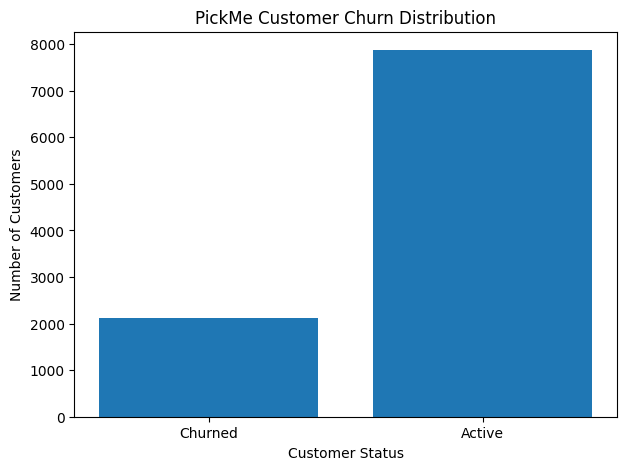

In [ ]:
churn_pd = df_processed.groupBy("churn").count().toPandas()

churn_pd["Status"] = churn_pd["churn"].map({
    0: "Active",
    1: "Churned"
})

plt.figure(figsize=(7,5))

plt.bar(
    churn_pd["Status"],
    churn_pd["count"]
)

plt.title("PickMe Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.show()

Compare customer behaviour

In [ ]:
df_processed.groupBy("churn").agg(
    round(avg("monthly trips"), 2).alias("Average Monthly Trips"),
    round(avg("total trips 6m"), 2).alias("Average Trips - 6 Months"),
    round(avg("monthly spend LKR"), 2).alias("Average Monthly Spend"),
    round(avg("avg rating"), 2).alias("Average Rating"),
    round(avg("cancellation rate"), 3).alias("Cancellation Rate"),
    round(avg("avg_wait_time_min"), 2).alias("Average Waiting Time"),
    round(avg("promo_usage_rate"), 3).alias("Promo Usage Rate"),
    round(avg("support_contacts_6m"), 2).alias("Support Contacts"),
    round(avg("last_ride_days_ago"), 2).alias("Days Since Last Ride")
).show()

+-----+---------------------+------------------------+---------------------+--------------+-----------------+--------------------+----------------+----------------+--------------------+
|churn|Average Monthly Trips|Average Trips - 6 Months|Average Monthly Spend|Average Rating|Cancellation Rate|Average Waiting Time|Promo Usage Rate|Support Contacts|Days Since Last Ride|
+-----+---------------------+------------------------+---------------------+--------------+-----------------+--------------------+----------------+----------------+--------------------+
|    1|                 8.76|                    43.8|               7546.6|          4.18|            0.153|               10.73|           0.391|            1.31|               78.28|
|    0|                 9.03|                   45.22|              7693.46|          4.26|             0.14|                8.57|           0.403|            1.17|               56.07|
+-----+---------------------+------------------------+----------------

Analyze waiting time

In [ ]:
df_processed.groupBy("churn").agg(
    round(avg("avg_wait_time_min"), 2).alias("Average Waiting Time")
).show()

+-----+--------------------+
|churn|Average Waiting Time|
+-----+--------------------+
|    1|               10.73|
|    0|                8.57|
+-----+--------------------+



Analyze last ride behaviour

In [ ]:
df_processed.groupBy("churn").agg(
    round(avg("last_ride_days_ago"), 2).alias("Average Days Since Last Ride")
).show()

+-----+----------------------------+
|churn|Average Days Since Last Ride|
+-----+----------------------------+
|    1|                       78.28|
|    0|                       56.07|
+-----+----------------------------+



Analyze ratings

In [ ]:
df_processed.groupBy("churn").agg(
    round(avg("avg rating"), 2).alias("Average Customer Rating")
).show()

+-----+-----------------------+
|churn|Average Customer Rating|
+-----+-----------------------+
|    1|                   4.18|
|    0|                   4.26|
+-----+-----------------------+



Analyze cancellations

In [ ]:
df_processed.groupBy("churn").agg(
    round(avg("cancellation rate"), 3).alias("Average Cancellation Rate")
).show()

+-----+-------------------------+
|churn|Average Cancellation Rate|
+-----+-------------------------+
|    1|                    0.153|
|    0|                     0.14|
+-----+-------------------------+



Analyze support contacts

In [ ]:
df_processed.groupBy("churn").agg(
    round(avg("support_contacts_6m"), 2).alias("Average Support Contacts")
).show()

+-----+------------------------+
|churn|Average Support Contacts|
+-----+------------------------+
|    1|                    1.31|
|    0|                    1.17|
+-----+------------------------+



Analyze cities

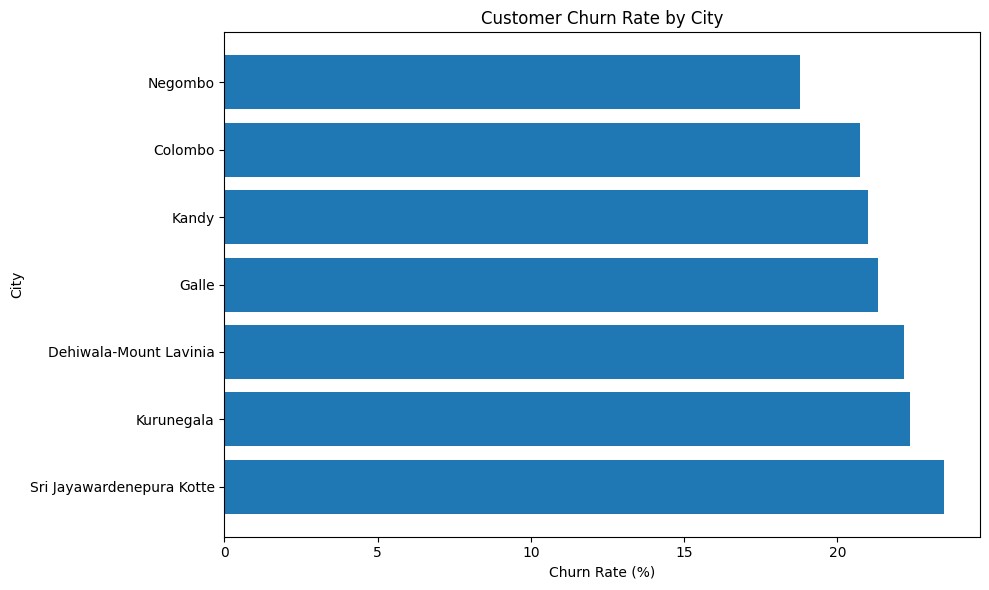

In [ ]:
city_pd = city_churn.toPandas()

plt.figure(figsize=(10,6))

plt.barh(
    city_pd["city"],
    city_pd["Churn Rate (%)"]
)

plt.title("Customer Churn Rate by City")
plt.xlabel("Churn Rate (%)")
plt.ylabel("City")

plt.tight_layout()
plt.show()

Analyze payment methods

In [ ]:
payment_churn = df_processed.groupBy("payment_method").agg(
    round(avg("churn") * 100, 2).alias("Churn Rate (%)")
).orderBy(
    col("Churn Rate (%)").desc()
)

payment_churn.show()

+--------------+--------------+
|payment_method|Churn Rate (%)|
+--------------+--------------+
|          Cash|         21.81|
| PickMe Wallet|         20.87|
|          Card|         20.49|
+--------------+--------------+



Convert to Pandas for more visualizations

In [ ]:
analysis_pd = df_processed.toPandas()

print(analysis_pd.shape)
analysis_pd.head()

(10000, 17)


,customer ID,age,gender,city,signup month,monthly trips,total trips 6m,avg fare lkr,monthly spend LKR,avg rating,cancellation rate,avg_wait_time_min,promo_usage_rate,payment_method,support_contacts_6m,last_ride_days_ago,churn
0,PM100000,56,Male,Colombo,2025-03-01,9,45,1448.12,13033.08,4.35,0.051,13.3,0.412,Cash,3,74,0
1,PM100001,46,Female,Colombo,2024-05-01,8,32,756.27,6050.16,4.13,0.083,7.0,0.176,Cash,1,63,0
2,PM100002,32,Male,Galle,2025-07-01,9,36,962.62,8663.58,4.00,0.064,8.1,0.777,Cash,1,43,0
3,PM100003,60,Female,Negombo,2024-10-01,7,28,704.82,4933.74,4.31,0.064,11.6,0.145,Card,2,66,1
4,PM100004,25,Male,Colombo,2024-09-01,6,24,1360.51,8163.06,3.86,0.081,5.0,0.946,PickMe Wallet,1,47,0


Churn vs waiting time

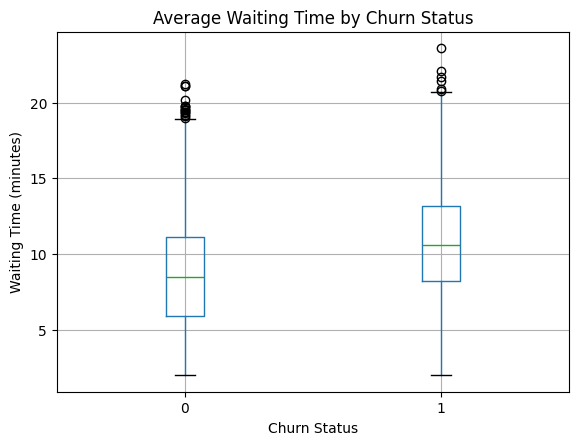

In [ ]:
analysis_pd.boxplot(
    column="avg_wait_time_min",
    by="churn"
)

plt.title("Average Waiting Time by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Waiting Time (minutes)")

plt.show()

Feature engineering

Customer activity level

In [ ]:
from pyspark.sql.functions import when

df_features = df_processed.withColumn(
    "activity_level",
    when(col("monthly trips") >= 10, "High")
    .when(col("monthly trips") >= 5, "Medium")
    .otherwise("Low")
)

Inactivity risk

In [ ]:
df_features = df_features.withColumn(
    "inactivity_risk",
    when(col("last_ride_days_ago") >= 60, 1)
    .otherwise(0)
)

High waiting time

In [ ]:
df_features = df_features.withColumn(
    "high_wait_time",
    when(col("avg_wait_time_min") >= 10, 1)
    .otherwise(0)
)

In [ ]:
df_features.select(
    "customer ID",
    "monthly trips",
    "last_ride_days_ago",
    "activity_level",
    "inactivity_risk",
    "high_wait_time",
    "churn"
).show(10)

+-----------+-------------+------------------+--------------+---------------+--------------+-----+
|customer ID|monthly trips|last_ride_days_ago|activity_level|inactivity_risk|high_wait_time|churn|
+-----------+-------------+------------------+--------------+---------------+--------------+-----+
|   PM100000|            9|                74|        Medium|              1|             1|    0|
|   PM100001|            8|                63|        Medium|              1|             0|    0|
|   PM100002|            9|                43|        Medium|              0|             0|    0|
|   PM100003|            7|                66|        Medium|              1|             1|    1|
|   PM100004|            6|                47|        Medium|              0|             0|    0|
|   PM100005|            7|                64|        Medium|              1|             0|    0|
|   PM100006|            6|                13|        Medium|              0|             0|    0|
|   PM1000

PySpark Machine Learning
Prepare ML data

In [ ]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline

Define features

In [ ]:
categorical_cols = [
    "gender",
    "city",
    "payment_method"
]

numerical_cols = [
    "age",
    "monthly trips",
    "total trips 6m",
    "avg fare lkr",
    "monthly spend LKR",
    "avg rating",
    "cancellation rate",
    "avg_wait_time_min",
    "promo_usage_rate",
    "support_contacts_6m",
    "last_ride_days_ago"
]

Convert categorical variables

In [ ]:
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_index",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoder = OneHotEncoder(
    inputCols=[c + "_index" for c in categorical_cols],
    outputCols=[c + "_encoded" for c in categorical_cols]
)

Create feature vector

In [ ]:
assembler = VectorAssembler(
    inputCols=
        numerical_cols +
        [c + "_encoded" for c in categorical_cols],
    outputCol="features"
)

Logistic Regression model

In [ ]:
lr = LogisticRegression(
    featuresCol="features",
    labelCol="churn",
    maxIter=100
)

Build the complete ML pipeline

In [ ]:
pipeline = Pipeline(
    stages=indexers + [encoder, assembler, lr]
)

Split the data

In [ ]:
train_data, test_data = df_processed.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_data.count())
print("Testing records:", test_data.count())

Training records: 8079
Testing records: 1921


Train the model

In [ ]:
model = pipeline.fit(train_data)

print("Model training completed.")

Model training completed.


Make predictions

In [ ]:
predictions = model.transform(test_data)

predictions.select(
    "customer ID",
    "churn",
    "prediction",
    "probability"
).show(20, truncate=False)

+-----------+-----+----------+-----------------------------------------+
|customer ID|churn|prediction|probability                              |
+-----------+-----+----------+-----------------------------------------+
|PM100002   |0    |0.0       |[0.9042949961869253,0.09570500381307467] |
|PM100006   |0    |0.0       |[0.926478972455794,0.07352102754420597]  |
|PM100008   |0    |0.0       |[0.862477660856154,0.13752233914384604]  |
|PM100013   |1    |0.0       |[0.5968579690902885,0.40314203090971146] |
|PM100019   |0    |0.0       |[0.9413908387001467,0.058609161299853274]|
|PM100023   |0    |0.0       |[0.9374880901077058,0.06251190989229416] |
|PM100029   |0    |0.0       |[0.5742922362936889,0.42570776370631114] |
|PM100035   |0    |0.0       |[0.6479647910770789,0.35203520892292106] |
|PM100045   |1    |1.0       |[0.326026529635003,0.673973470364997]    |
|PM100046   |0    |0.0       |[0.8716167299495653,0.1283832700504347]  |
|PM100047   |0    |0.0       |[0.9436115819443124,0

Evaluate accuracy

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = accuracy_evaluator.evaluate(predictions)

print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8011


Precision

In [ ]:
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

precision = precision_evaluator.evaluate(predictions)

print(f"Precision: {precision:.4f}")

Precision: 0.7706


Recall

In [ ]:
recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="weightedRecall"
)

recall = recall_evaluator.evaluate(predictions)

print(f"Recall: {recall:.4f}")

Recall: 0.8011


F1 score

In [ ]:
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="churn",
    predictionCol="prediction",
    metricName="f1"
)

f1 = f1_evaluator.evaluate(predictions)

print(f"F1 Score: {f1:.4f}")

F1 Score: 0.7568


Confusion matrix

In [ ]:
confusion_matrix = predictions.groupBy(
    "churn",
    "prediction"
).count().orderBy(
    "churn",
    "prediction"
)

confusion_matrix.show()

+-----+----------+-----+
|churn|prediction|count|
+-----+----------+-----+
|    0|       0.0| 1463|
|    0|       1.0|   49|
|    1|       0.0|  333|
|    1|       1.0|   76|
+-----+----------+-----+



| Actual | Predicted | Meaning        |
| ------ | --------- | -------------- |
| 0      | 0         | True Negative  |
| 0      | 1         | False Positive |
| 1      | 0         | False Negative |
| 1      | 1         | True Positive  |


Identify the most important churn factors

In [ ]:
lr_model = model.stages[-1]

coefficients = lr_model.coefficients.toArray()

print("Number of model coefficients:", len(coefficients))

Number of model coefficients: 23


In [ ]:
print("Intercept:", lr_model.intercept)

print("\nLogistic Regression Coefficients:")

for feature, coefficient in zip(
    assembler.getInputCols(),
    lr_model.coefficients
):
    print(feature, coefficient)

Intercept: -1.9822350195563938

Logistic Regression Coefficients:
age -0.0038590876646478274
monthly trips -0.03299884325142136
total trips 6m -0.0025518101264202986
avg fare lkr -3.858495269467636e-05
monthly spend LKR 8.892819360969373e-06
avg rating -0.5360471207953987
cancellation rate 2.03939666786049
avg_wait_time_min 0.1694460586781885
promo_usage_rate -0.3346929282415769
support_contacts_6m 0.10259204150531975
last_ride_days_ago 0.022315393306424222
gender_encoded 0.07720475139878173
city_encoded -0.0772047513987686
payment_method_encoded -0.024147034506391607


Random Forest model

In [ ]:
from pyspark.ml.classification import RandomForestClassifier

create

In [ ]:
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="churn",
    numTrees=100,
    seed=42
)

create pipeline

In [ ]:
rf_pipeline = Pipeline(
    stages=indexers + [encoder, assembler, rf]
)

Train

In [ ]:
rf_model = rf_pipeline.fit(train_data)

Predict

In [ ]:
rf_predictions = rf_model.transform(test_data)

rf_predictions.select(
    "customer ID",
    "churn",
    "prediction",
    "probability"
).show(20, truncate=False)

+-----------+-----+----------+----------------------------------------+
|customer ID|churn|prediction|probability                             |
+-----------+-----+----------+----------------------------------------+
|PM100002   |0    |0.0       |[0.8464680685244097,0.15353193147559033]|
|PM100006   |0    |0.0       |[0.8344513217320644,0.1655486782679357] |
|PM100008   |0    |0.0       |[0.8438844713958872,0.1561155286041128] |
|PM100013   |1    |0.0       |[0.7608622008170446,0.23913779918295552]|
|PM100019   |0    |0.0       |[0.865202000093965,0.13479799990603494] |
|PM100023   |0    |0.0       |[0.8619335778418877,0.13806642215811216]|
|PM100029   |0    |0.0       |[0.6910388291045022,0.30896117089549785]|
|PM100035   |0    |0.0       |[0.7376740513620687,0.2623259486379314] |
|PM100045   |1    |0.0       |[0.6164888719330799,0.38351112806692]   |
|PM100046   |0    |0.0       |[0.8003501701308785,0.1996498298691215] |
|PM100047   |0    |0.0       |[0.8623389604411588,0.137661039558

Evaluate

In [ ]:
rf_accuracy = accuracy_evaluator.evaluate(rf_predictions)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")

Random Forest Accuracy: 0.7871


Findings

1.Overall customer churn rate = 21.25%. - This means roughly 1 in every 5 customers in the dataset is classified as churned.

2.Waiting time - The churned group experienced approximately 2.2 additional minutes of average waiting time.

3.Customer rating - Lower customer ratings are associated with churn, but this factor appears less differentiated than inactivity and waiting time in the descriptive analysis.

4.Cancellation - Churned customers show somewhat higher cancellation rates.


Recommendations

1.Early inactivity detection - PickMe could create an automated customer retention trigger.

2.Reduce waiting time - The analysis indicates that churned customers have higher average waiting times.

3.Customer experience monitoring.
Monitor;
Customer ratings,
Cancellation rates,
Waiting times,
Support contacts,

4.Predictive churn system.